In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import json
import os
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

In [2]:
reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)


In [3]:
print(combined_df.columns)


Index(['subreddit', 'author', 'date', 'post', 'automated_readability_index',
       'coleman_liau_index', 'flesch_kincaid_grade_level',
       'flesch_reading_ease', 'gulpease_index', 'gunning_fog_index',
       ...
       'tfidf_without', 'tfidf_wonder', 'tfidf_work', 'tfidf_worri',
       'tfidf_wors', 'tfidf_would', 'tfidf_wrong', 'tfidf_x200b', 'tfidf_year',
       'subreddit_name'],
      dtype='object', length=351)


In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import joblib
import pandas as pd

#  Prepare Reddit labels
depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']
combined_df['label'] = combined_df['subreddit_name'].apply(lambda x: 1 if x in depressive_subs else 0)

#  Fit a TF-IDF vectorizer on Reddit text
reddit_texts = combined_df['post'].astype(str)
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X = vectorizer.fit_transform(reddit_texts)
y = combined_df['label']

#  Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#  Train SVM
svm = LinearSVC(C=1.0, class_weight='balanced', max_iter=5000)
svm.fit(X_train, y_train)

#  Evaluate on Reddit test set
y_pred = svm.predict(X_test)
print(" Reddit Accuracy:", accuracy_score(y_test, y_pred))
print("\n Reddit Classification Report:\n", classification_report(y_test, y_pred))

#  Save model and vectorizer for later Twitter predictions
joblib.dump(svm, "svm_reddit_tfidf.pkl")
joblib.dump(vectorizer, "tfidf_reddit_vectorizer.pkl")


✅ Reddit Accuracy: 0.9341476154124312

📊 Reddit Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.94      0.95     16982
           1       0.88      0.92      0.90      7907

    accuracy                           0.93     24889
   macro avg       0.92      0.93      0.93     24889
weighted avg       0.94      0.93      0.93     24889



['tfidf_reddit_vectorizer.pkl']

In [37]:
import joblib

# After training your model and vectorizer
joblib.dump(svm, "svm_reddit_tfidf.pkl")          # save trained SVM
joblib.dump(vectorizer, "tfidf_reddit_vectorizer.pkl")  # save TF-IDF vectorizer


['tfidf_reddit_vectorizer.pkl']

In [38]:
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")
print(twitter_df.columns)


Index(['Unnamed: 0', 'post_id', 'post_created', 'post_text', 'user_id',
       'followers', 'friends', 'favourites', 'statuses', 'retweets', 'label'],
      dtype='object')


✅ Twitter Accuracy: 0.5718

📊 Twitter Classification Report:
               precision    recall  f1-score   support

           0       0.54      0.90      0.68     10000
           1       0.70      0.25      0.37     10000

    accuracy                           0.57     20000
   macro avg       0.62      0.57      0.52     20000
weighted avg       0.62      0.57      0.52     20000



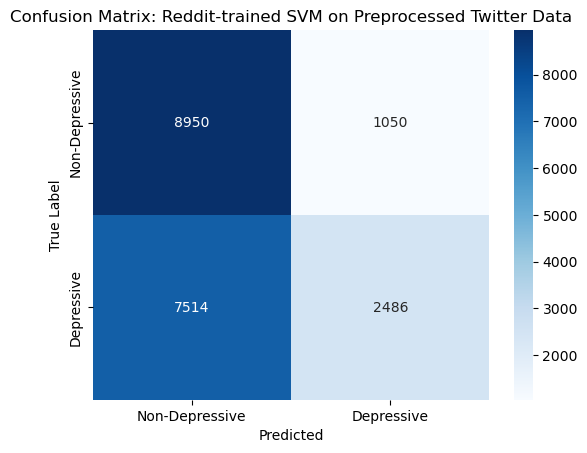

In [39]:
import pandas as pd
import joblib
import re
import string
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


# Load trained Reddit SVM and TF-IDF vectorizer

svm = joblib.load("svm_reddit_tfidf.pkl")
vectorizer = joblib.load("tfidf_reddit_vectorizer.pkl")


# Load Twitter dataset

twitter_df = pd.read_csv("Mental-Health-Twitter.csv")


# Preprocess Twitter text

def preprocess_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)      # remove URLs
    text = re.sub(r"@\w+", "", text)                # remove mentions
    text = re.sub(r"#(\w+)", r"\1", text)           # remove # but keep word
    text = re.sub(r"[^\w\s,]", "", text)            # remove emojis/symbols/punctuation
    text = re.sub(r'\d+', '', text)                 # remove numbers
    text = re.sub(r'\s+', ' ', text).strip()        # normalize spaces
    return text

twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_tweet)


# Transform Twitter text using Reddit TF-IDF vectorizer

X_twitter = vectorizer.transform(twitter_df["clean_text"])
y_twitter = twitter_df["label"]


# Predict using Reddit-trained SVM

predicted_depression = svm.predict(X_twitter)


# Evaluate performance

print(" Twitter Accuracy:", accuracy_score(y_twitter, predicted_depression))
print("\nTwitter Classification Report:\n", classification_report(y_twitter, predicted_depression, zero_division=0))

# ------------------------------
# Visualize confusion matrix
# ------------------------------
cm = confusion_matrix(y_twitter, predicted_depression)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-Depressive", "Depressive"],
            yticklabels=["Non-Depressive", "Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix: Reddit-trained SVM on Preprocessed Twitter Data")
plt.show()


Twitter Accuracy: 0.5

Classification Report:
               precision    recall  f1-score   support

           0       0.50      1.00      0.67     10000
           1       0.00      0.00      0.00     10000

    accuracy                           0.50     20000
   macro avg       0.25      0.50      0.33     20000
weighted avg       0.25      0.50      0.33     20000



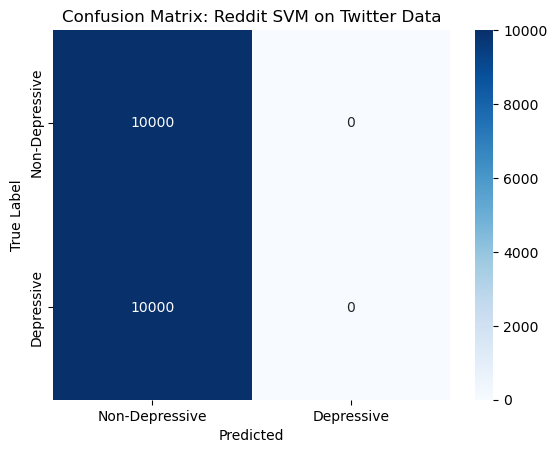

In [7]:
import pandas as pd
import joblib
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

#  Load trained Reddit SVM and TF-IDF vectorizer 
svm = joblib.load("svm_reddit_tfidf.pkl")
vectorizer = joblib.load("tfidf_reddit_vectorizer.pkl")  # if you saved it earlier

#  Load Twitter dataset 
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")

#  Prepare features and labels 
X_twitter = vectorizer.transform(twitter_df['post_text'].astype(str))
y_twitter = twitter_df['label']

#  Predict using Reddit-trained SVM 
twitter_preds = svm.predict(X_twitter)

#  Map Reddit subreddit predictions to Depressive / Non-Depressive 
depressive_subs = ["suicidewatch", "anxiety", "depression", "mentalhealth", "addiction", "alcoholism"]
predicted_depression = [1 if p in depressive_subs else 0 for p in twitter_preds]

#  Evaluate performance 
print("Twitter Accuracy:", accuracy_score(y_twitter, predicted_depression))
print("\nClassification Report:\n", classification_report(y_twitter, predicted_depression, zero_division=0))

#  Confusion matrix 
cm = confusion_matrix(y_twitter, predicted_depression)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Non-Depressive","Depressive"],
            yticklabels=["Non-Depressive","Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix: Reddit SVM on Twitter Data")
plt.show()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


 Twitter Accuracy: 0.57245

Twitter Classification Report:
               precision    recall  f1-score   support

           0       0.55      0.84      0.66     10000
           1       0.66      0.30      0.42     10000

    accuracy                           0.57     20000
   macro avg       0.60      0.57      0.54     20000
weighted avg       0.60      0.57      0.54     20000



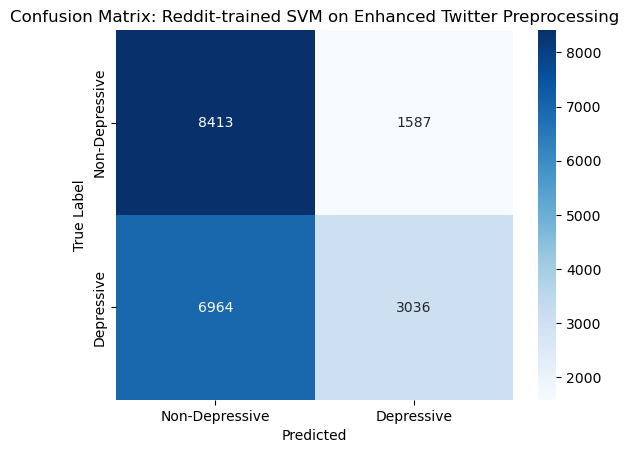

In [6]:
import pandas as pd
import joblib
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


# Setup and load model/vectorizer

nltk.download('stopwords')
nltk.download('wordnet')

svm = joblib.load("svm_reddit_tfidf.pkl")
vectorizer = joblib.load("tfidf_reddit_vectorizer.pkl")


# Load Twitter dataset

twitter_df = pd.read_csv("Mental-Health-Twitter.csv")


# Preprocessing pipeline

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)      # remove URLs
    text = re.sub(r"@\w+", "", text)                # remove mentions
    text = re.sub(r"#(\w+)", r"\1", text)           # remove # but keep word
    text = re.sub(r"[^a-z\s]", "", text)            # remove punctuation, numbers, symbols
    text = re.sub(r'\s+', ' ', text).strip()        # normalize spaces
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_tweet)


# Transform Twitter text using Reddit TF-IDF vectorizer

X_twitter = vectorizer.transform(twitter_df["clean_text"])
y_twitter = twitter_df["label"]


# Predict using Reddit-trained SVM

predicted_depression = svm.predict(X_twitter)


# Evaluate performance

print(" Twitter Accuracy:", accuracy_score(y_twitter, predicted_depression))
print("\nTwitter Classification Report:\n",
      classification_report(y_twitter, predicted_depression, zero_division=0))


# Visualize confusion matrix

cm = confusion_matrix(y_twitter, predicted_depression)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-Depressive", "Depressive"],
            yticklabels=["Non-Depressive", "Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix: Reddit-trained SVM on Enhanced Twitter Preprocessing")
plt.show()

# ------------------------------
# Suggested improvements:

#  - Re-train Reddit SVM using bi-grams/trigrams and sublinear_tf=True in TF-IDF:
#    vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1,3), sublinear_tf=True)
#  - Apply GridSearchCV to find best ‘C’ for SVM
#  - Try LogisticRegression, SGDClassifier, or fine-tuned BERT baseline for comparison


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


 Twitter train size (20%): 4000
 Twitter test size (100%): 20000
 Combined training dataset size: 128444
 Model saved as 'svm_reddit_twitter_mixed.pkl'
 Test Accuracy on Twitter: 0.63525

 Classification Report (Twitter test set):
               precision    recall  f1-score   support

           0       0.61      0.77      0.68     10000
           1       0.68      0.50      0.58     10000

    accuracy                           0.64     20000
   macro avg       0.65      0.64      0.63     20000
weighted avg       0.65      0.64      0.63     20000



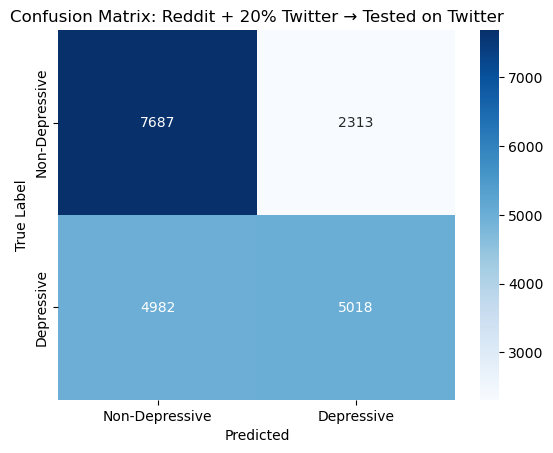

In [5]:
# ============================================================
#  TRAIN: Reddit + 20% Twitter | TEST: Full Twitter dataset
# ============================================================

import pandas as pd
import joblib
import re
import nltk
import seaborn as sns
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


#  Load Reddit datasets

reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)


#  Label Reddit data

depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']
combined_df['label'] = combined_df['subreddit_name'].apply(lambda x: 1 if x in depressive_subs else 0)


# Setup text preprocessing

nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)


#  Load and preprocess Twitter dataset

twitter_df = pd.read_csv("Mental-Health-Twitter.csv")
twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_text)
twitter_df["label"] = twitter_df["label"].astype(int)


#  Split Twitter dataset (20% for training mix, 80% for testing)


from sklearn.model_selection import train_test_split

twitter_train, _ = train_test_split(
    twitter_df,
    train_size=0.2,
    random_state=42,
    stratify=twitter_df["label"]
)

twitter_test = twitter_df.copy()  # use 100% of Twitter for testing

print(f" Twitter train size (20%): {len(twitter_train)}")
print(f" Twitter test size (100%): {len(twitter_test)}")


#  Prepare Reddit + 20% Twitter combined training dataset

reddit_df = combined_df.copy()
reddit_df["clean_text"] = reddit_df["post"].astype(str).apply(preprocess_text)

train_mix = pd.concat([reddit_df, twitter_train], ignore_index=True)
print(f" Combined training dataset size: {len(train_mix)}")


#  TF-IDF Vectorization on combined train data

vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1,2), sublinear_tf=True)
X_train = vectorizer.fit_transform(train_mix["clean_text"])
y_train = train_mix["label"]

# Save vectorizer for future inference
joblib.dump(vectorizer, "tfidf_reddit_twitter_vectorizer.pkl")


#  Train SVM on Reddit + 20% Twitter

svm = LinearSVC(C=1.0, class_weight='balanced', max_iter=5000)
svm.fit(X_train, y_train)
joblib.dump(svm, "svm_reddit_twitter_mixed.pkl")
print(" Model saved as 'svm_reddit_twitter_mixed.pkl'")


#  Test model on full Twitter dataset

vectorizer = joblib.load("tfidf_reddit_twitter_vectorizer.pkl")
svm = joblib.load("svm_reddit_twitter_mixed.pkl")

X_test = vectorizer.transform(twitter_test["clean_text"])
y_test = twitter_test["label"]

y_pred = svm.predict(X_test)


#  Evaluate model

print(" Test Accuracy on Twitter:", accuracy_score(y_test, y_pred))
print("\n Classification Report (Twitter test set):\n",
      classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-Depressive", "Depressive"],
            yticklabels=["Non-Depressive", "Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix: Reddit + 20% Twitter → Tested on Twitter")
plt.show()


<>:77: SyntaxWarning: invalid escape sequence '\ '
<>:77: SyntaxWarning: invalid escape sequence '\ '
C:\Users\Minhtu\AppData\Local\Temp\ipykernel_25392\1489237275.py:77: SyntaxWarning: invalid escape sequence '\ '
  print("\ Model Evaluation on Full Twitter Dataset:")
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


 Loaded Twitter dataset: (20000, 12)
label
1    10000
0    10000
Name: count, dtype: int64
 TF-IDF vectorizer saved as 'tfidf_twitter_full_vectorizer.pkl'
 Model saved as 'svm_twitter_full.pkl'
\ Model Evaluation on Full Twitter Dataset:
Accuracy: 0.9196

 Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.93      0.92     10000
           1       0.92      0.91      0.92     10000

    accuracy                           0.92     20000
   macro avg       0.92      0.92      0.92     20000
weighted avg       0.92      0.92      0.92     20000



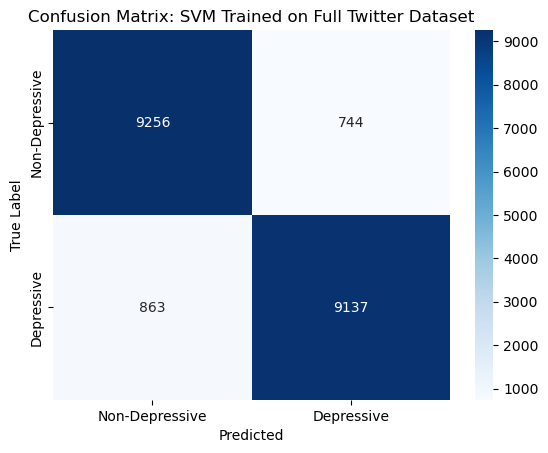

In [3]:
# ============================================================
#  TRAIN + EVALUATE: Full Twitter Dataset 
# ============================================================

import pandas as pd
import joblib
import re
import nltk
import seaborn as sns
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


#  Setup text preprocessing

nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

#  Load and preprocess Twitter dataset

twitter_df = pd.read_csv("Mental-Health-Twitter.csv")
twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_text)
twitter_df["label"] = twitter_df["label"].astype(int)

print(" Loaded Twitter dataset:", twitter_df.shape)
print(twitter_df["label"].value_counts())


#  TF-IDF Vectorization on full dataset

vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1,2), sublinear_tf=True)
X = vectorizer.fit_transform(twitter_df["clean_text"])
y = twitter_df["label"]

# Save vectorizer
joblib.dump(vectorizer, "tfidf_twitter_full_vectorizer.pkl")
print(" TF-IDF vectorizer saved as 'tfidf_twitter_full_vectorizer.pkl'")


#  Train SVM on full Twitter data

svm = LinearSVC(C=1.0, class_weight='balanced', max_iter=5000)
svm.fit(X, y)

# Save trained model
joblib.dump(svm, "svm_twitter_full.pkl")
print(" Model saved as 'svm_twitter_full.pkl'")


#  Evaluate on the same dataset (self-evaluation)

y_pred = svm.predict(X)

accuracy = accuracy_score(y, y_pred)
report = classification_report(y, y_pred, zero_division=0)
cm = confusion_matrix(y, y_pred)

print("\ Model Evaluation on Full Twitter Dataset:")
print("Accuracy:", round(accuracy, 4))
print("\n Classification Report:\n", report)


#  Confusion Matrix Visualization

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-Depressive", "Depressive"],
            yticklabels=["Non-Depressive", "Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix: SVM Trained on Full Twitter Dataset")
plt.show()


 Loaded pretrained SVM model and TF-IDF vectorizer.


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


 Preprocessing Reddit text...

 Accuracy on Reddit dataset: 0.4287

 Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.17      0.29     84907
           1       0.35      0.97      0.52     39537

    accuracy                           0.43    124444
   macro avg       0.65      0.57      0.41    124444
weighted avg       0.75      0.43      0.37    124444



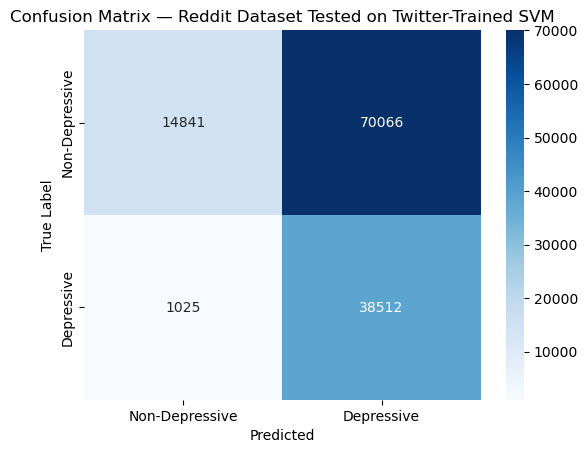


 Accuracy per subreddit:
  addiction       → 0.9769
  adhd            → 0.0295
  alcoholism      → 0.9586
  anxiety         → 0.9854
  conspiracy      → 0.3260
  fitness         → 0.0523
  jokes           → 0.4226
  meditation      → 0.0835
  mentalhealth    → 0.9865
  relationship    → 0.0098
  suicidewatch    → 0.9565
  teaching        → 0.0871


In [2]:
# ============================================================
#  TEST TWITTER-TRAINED MODEL ON REDDIT DATASET 
# ============================================================

import pandas as pd
import joblib
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


#  Load saved model + vectorizer

vectorizer = joblib.load("tfidf_twitter_full_vectorizer.pkl")
svm = joblib.load("svm_twitter_full.pkl")
print(" Loaded pretrained SVM model and TF-IDF vectorizer.")


#  Setup preprocessing 

nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)


#  Load Reddit datasets

reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)


#  Preprocess Reddit posts

print(" Preprocessing Reddit text...")
combined_df['clean_post'] = combined_df['post'].astype(str).apply(preprocess_text)


#  Label Reddit data

depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']
combined_df['label'] = combined_df['subreddit_name'].apply(lambda x: 1 if x in depressive_subs else 0)


# Transform Reddit data using Twitter vectorizer

X_test = vectorizer.transform(combined_df['clean_post'])
y_test = combined_df['label']


#  Predict using the Twitter-trained SVM model

y_pred = svm.predict(X_test)


#  Evaluate results

accuracy = accuracy_score(y_test, y_pred)
print(f"\n Accuracy on Reddit dataset: {accuracy:.4f}")

print("\n Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-Depressive", "Depressive"],
            yticklabels=["Non-Depressive", "Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix — Reddit Dataset Tested on Twitter-Trained SVM")
plt.show()

# Per-subreddit accuracy

print("\n Accuracy per subreddit:")
for name, group in combined_df.groupby('subreddit_name'):
    acc = accuracy_score(group['label'], y_pred[group.index])
    print(f"  {name:<15} → {acc:.4f}")
